In [1]:
!pip install arviz arviz_base arviz_stats arviz_plots
#!pip install "arviz==0.23.0" --force-reinstall --no-deps
!pip install nutpie pymc
!pip install h5netcdf
#!pip install -U arviz


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import numpy as np
import pandas as pd

import pymc as pm
import nutpie

import arviz as az
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(123)

Shape: (432, 11)
   lot  type  coform  temp_C  temp_K  time_months     potency  lot_idx  \
0    1     0       0       5  278.15            0  102.798868        0   
1    1     0       0       5  278.15            1   99.229236        0   
2    1     0       0       5  278.15            3  100.904459        0   
3    1     0       0       5  278.15            6   99.117985        0   
4    1     0       0       5  278.15            9   94.853585        0   

   type_idx  coform_idx  log_potency  
0         0           0     4.632774  
1         0           0     4.597433  
2         0           0     4.614174  
3         0           0     4.596311  
4         0           0     4.552334  


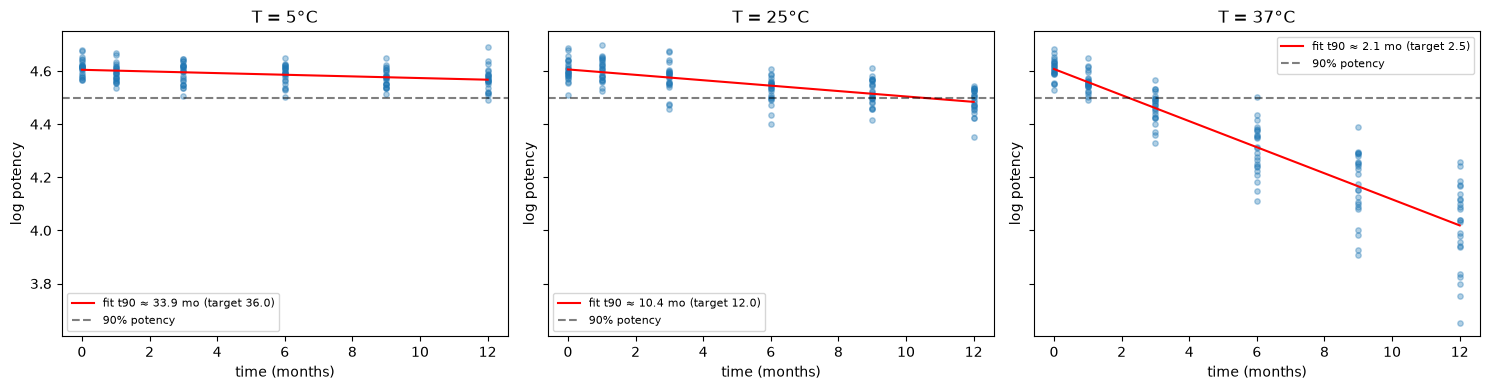

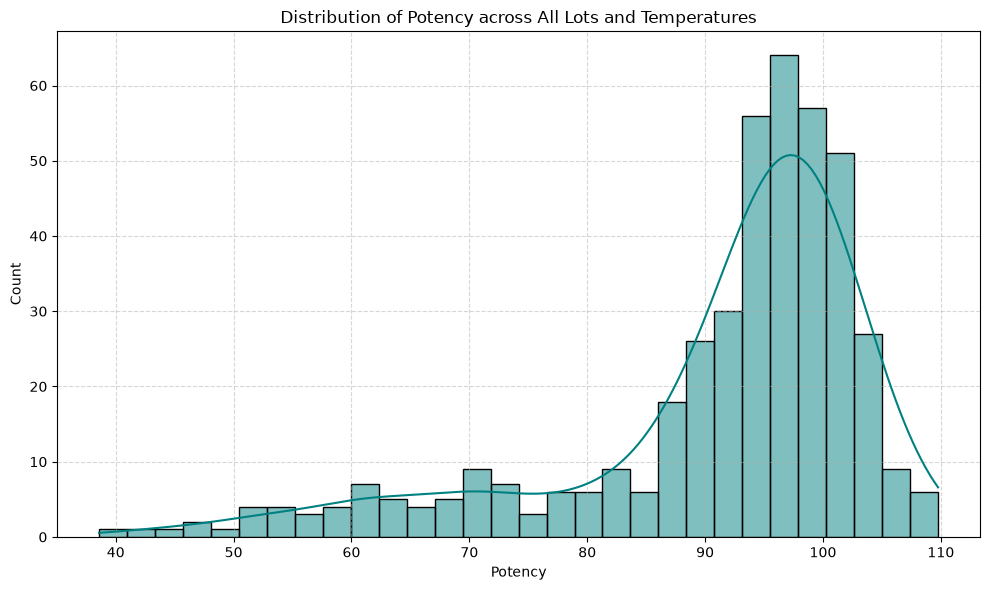

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

rng = np.random.default_rng(123)

temps_C = [5, 25, 37]
n_type, n_coform, n_lots_per_combo = 3, 2, 4
timepoints = [0, 1, 3, 6, 9, 12]

# ---- t90 targets ----
t90_targets = {5: 36.0, 25: 12.0, 37: 2.5}          # months
# potency(t) = 100 * exp(-k t)  =>  t90 = -ln(0.9) / k
k_base = {T: -np.log(0.9) / t90 for T, t90 in t90_targets.items()}

rows = []
lot_counter = 0
for hpv_type in range(n_type):
    for coform in range(n_coform):
        type_factor   = np.exp(0.10 * hpv_type)     # multiplicative on k
        coform_factor = np.exp(0.05 * coform)
        for lot in range(n_lots_per_combo):
            lot_counter += 1
            log_noise = rng.normal(0, 0.15)          # lot-to-lot lognormal on k
            intercept = rng.normal(np.log(100), 0.03)
            for temp_C in temps_C:
                T = temp_C + 273.15
                k = k_base[temp_C] * type_factor * coform_factor * np.exp(log_noise)
                for time in timepoints:
                    logpot  = intercept - k * time + rng.normal(0, 0.03)
                    potency = np.exp(logpot)
                    if potency > 10.0:
                        rows.append([lot_counter, hpv_type, coform, temp_C, T,
                                     time, potency])

df = pd.DataFrame(rows, columns=["lot", "type", "coform", "temp_C", "temp_K",
                                  "time_months", "potency"])
df["lot_idx"]     = df["lot"].astype("category").cat.codes
df["type_idx"]    = df["type"].astype("category").cat.codes
df["coform_idx"]  = df["coform"].astype("category").cat.codes
df["log_potency"] = np.log(df["potency"])

print(f"Shape: {df.shape}")
print(df.head())

# ---- sanity check: fitted t90 per temperature ----
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, T in zip(axes, temps_C):
    sub = df[df["temp_C"] == T]
    slope, intercept_fit = np.polyfit(sub["time_months"], sub["log_potency"], 1)
    k_fit   = -slope
    t90_fit = -np.log(0.9) / k_fit
    tgrid   = np.linspace(sub["time_months"].min(), sub["time_months"].max(), 50)
    ax.scatter(sub["time_months"], sub["log_potency"], alpha=0.35, s=15)
    ax.plot(tgrid, intercept_fit + slope * tgrid, color="red",
            label=f"fit t90 ≈ {t90_fit:.1f} mo (target {t90_targets[T]})")
    ax.axhline(np.log(90), color="black", ls="--", alpha=0.5, label="90% potency")
    ax.set_title(f"T = {T}°C")
    ax.set_xlabel("time (months)")
    ax.set_ylabel("log potency")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# ---- original histogram ----
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x="potency", kde=True, color="teal", bins=30)
plt.title("Distribution of Potency across All Lots and Temperatures")
plt.xlabel("Potency"); plt.ylabel("Count")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [11]:
import pytensor.tensor as pt
import numpy as np
import pymc as pm

# Define missing physical constants
R = 8.314
T_REF = 278.15

n_lot    = df["lot_idx"].nunique()
n_type   = df["type_idx"].nunique()
n_coform = df["coform_idx"].nunique()

# One row per lot: its type and coform indices
lot_df      = df.drop_duplicates("lot_idx").sort_values("lot_idx").reset_index(drop=True)
lot_type    = lot_df["type_idx"].values.astype(int)     # shape (n_lot,)
lot_coform  = lot_df["coform_idx"].values.astype(int)   # shape (n_lot,)

# Observation-level arrays
lot_idx      = df["lot_idx"].values.astype(int)
temp_K       = df["temp_K"].values.astype(float)
time_months  = df["time_months"].values.astype(float)
log_potency  = df["log_potency"].values.astype(float)

coords = {
    "lot":    np.arange(n_lot),
    "type":   np.arange(n_type),
    "coform": np.arange(n_coform),
    "kin":    ["logk", "logEaR"],
    "obs":    np.arange(len(df)),
}

In [12]:
import pytensor.tensor as pt

n_lot = df["lot_idx"].nunique()
n_type = df["type_idx"].nunique()
n_coform = df["coform_idx"].nunique()

with pm.Model() as model:

    #
    # baseline potency     #

    alpha0 = pm.Normal(
        "alpha0",
        mu=df["log_potency"].mean(),
        sigma=1,
    )

    sigma_alpha = pm.HalfStudentT(
        "sigma_alpha",
        nu=4,
        sigma=1,
    )

    alpha_raw = pm.Normal(
        "alpha_raw",
        0,
        1,
        shape=n_lot,
    )

    alpha = pm.Deterministic(
        "alpha",
        alpha0 + sigma_alpha * alpha_raw,
    )

    #
    # type effects
    #

    sigma_type_k = pm.HalfNormal(
       "sigma_type_k",
        0.5
    )

    sigma_type_E = pm.HalfNormal(
        "sigma_type_E",
        0.5
    )

    type_k = pm.Normal(
       "type_k",
        0,
        sigma_type_k,
        shape=n_type
    )

    type_E = pm.Normal(
        "type_E",
        0,
        sigma_type_E,
        shape=n_type
    )

    #
    # coform effects
    #

    sigma_cf_k = pm.HalfNormal(
        "sigma_cf_k",
        0.5
    )

    sigma_cf_E = pm.HalfNormal(
        "sigma_cf_E",
        0.5
    )

    coform_k = pm.Normal(
        "coform_k",
        0,
        sigma_cf_k,
        shape=n_coform
    )

    coform_E = pm.Normal(
        "coform_E",
        0,
        sigma_cf_E,
        shape=n_coform
    )

    mu_logk = pm.Normal(
        "mu_logk",
        -3,
        1
    )

    mu_logEa = pm.Normal(
        "mu_logEaR",
        np.log(9000),
        0.3
    )

    #
    # lot correlation
    #

    chol, corr, stds = pm.LKJCholeskyCov(
        "lot_cov",
        n=2,
        eta=2,
        sd_dist=pm.HalfStudentT.dist(
        nu=4,
        sigma=0.5

        ),
    )


    lot_z = pm.Normal(
        "lot_z",
        0,
        1,
        shape=(n_lot,2)
    )

    lot_df = (
        df
        .drop_duplicates("lot_idx")
        .sort_values("lot_idx")
   )

    lot_mean = pt.stack(
        [
            mu_logk
            + type_k[lot_df["type_idx"].values]
            + coform_k[lot_df["coform_idx"].values],

            mu_logEa
            + type_E[lot_df["type_idx"].values]
            + coform_E[lot_df["coform_idx"].values],
       ],
       axis=1,
    )

    kinetics = pm.Deterministic(
        "kinetics",
        lot_mean + lot_z @ chol.T
    )

    logk = kinetics[:,0]
    logEa = kinetics[:,1]

    k_ref = pm.Deterministic(
        "k_ref",
        pm.math.exp(logk)
    )

    Ea = pm.Deterministic(
        "Ea",
        pm.math.exp(logEa)
    )

    arr_factor = pm.math.exp(
        (
            Ea[df["lot_idx"].values]
        )
        *
        (
            1/T_REF
           - 1/df.temp_K.values
        )
    )

    kT = (
        k_ref[df["lot_idx"].values]
        * arr_factor
    )

    mu = (
        alpha[df.lot_idx.values]
        -
        kT
        * df["time_months"].values
    )

    sigma = pm.HalfStudentT(
        "sigma",
        nu=4,
        sigma=1
    )

    nu = pm.Exponential(
        "n*",
        0.1
    )

    y = pm.StudentT(
        "y",
        nu=nu,
        mu=mu,
        sigma=sigma,
        observed=df["log_potency"].values

    )

    #
    # shelf life
    #

    T25 = 298.15

    k25 = (
        k_ref
        *
        pm.math.exp(
            Ea/R
            *
            (
                1/T_REF
                -
                1/T25
            )
        )
    )

    pm.Deterministic(
        "t90_25",
        np.log(10/9)/k25
    )

    pm.Deterministic(
    "corr_k_Ea",
    corr[0, 1],
)

In [54]:
with pm.Model(coords=coords) as model:

    # baseline potency
    alpha0 = pm.Normal("alpha0", mu=np.log(100), sigma=0.5)
    sigma_alpha = pm.HalfNormal("sigma_alpha", 0.1)
    alpha_raw = pm.Normal("alpha_raw", 0, 1, dims="lot")
    alpha = pm.Deterministic("alpha", alpha0 + sigma_alpha * alpha_raw, dims="lot")

    # type / coform effects (non-centred)
    sigma_type_k = pm.HalfNormal("sigma_type_k", 0.2)
    sigma_type_E = pm.HalfNormal("sigma_type_E", 0.2)
    sigma_cf_k   = pm.HalfNormal("sigma_cf_k",   0.2)
    sigma_cf_E   = pm.HalfNormal("sigma_cf_E",   0.2)

    type_k = pm.Deterministic(
        "type_k", sigma_type_k * pm.Normal("type_k_raw", 0, 1, dims="type"), dims="type"
    )
    type_E = pm.Deterministic(
        "type_E", sigma_type_E * pm.Normal("type_E_raw", 0, 1, dims="type"), dims="type"
    )
    coform_k = pm.Deterministic(
        "coform_k", sigma_cf_k * pm.Normal("coform_k_raw", 0, 1, dims="coform"), dims="coform"
    )
    coform_E = pm.Deterministic(
        "coform_E", sigma_cf_E * pm.Normal("coform_E_raw", 0, 1, dims="coform"), dims="coform"
    )

    mu_logk   = pm.Normal("mu_logk",   -3,              0.5)
    mu_logEaR = pm.Normal("mu_logEaR", np.log(9000.0),  0.3)   # Ea/R in kelvin

    # LKJ prior on the 2x2 lot-level covariance (log k_ref, log Ea/R)
    chol, corr, stds = pm.LKJCholeskyCov(
        "lot_cov",
        n=2,
        eta=2,
        sd_dist=pm.HalfNormal.dist(0.2),
    )
    lot_z = pm.Normal("lot_z", 0, 1, shape=(n_lot, 2))

    lot_mean = pt.stack(
        [
            mu_logk   + type_k[lot_type] + coform_k[lot_coform],
            mu_logEaR + type_E[lot_type] + coform_E[lot_coform],
        ],
        axis=1,
    )

    kinetics = pm.Deterministic("kinetics", lot_mean + lot_z @ chol.T, dims=("lot", "kin"))
    logk   = kinetics[:, 0]
    logEaR = kinetics[:, 1]

    # log k at each observation's temperature
    log_kT = logk[lot_idx] + pm.math.exp(logEaR[lot_idx]) * (1.0 / T_REF - 1.0 / temp_K)
    mu = alpha[lot_idx] - pm.math.exp(log_kT) * time_months

    sigma = pm.HalfNormal("sigma", 0.1)
    nu    = pm.Gamma("nu", alpha=2, beta=0.1)

    pm.StudentT(
        "y",
        nu=nu,
        mu=mu,
        sigma=sigma,
        observed=log_potency,
        dims="obs",
    )

    # derived quantities
    log_k25 = logk + pm.math.exp(logEaR) * (1.0 / T_REF - 1.0 / 298.15)
    pm.Deterministic("t90_25", np.log(10.0 / 9.0) / pm.math.exp(log_k25), dims="lot")
    pm.Deterministic("Ea",     R * pm.math.exp(logEaR), dims="lot")
    pm.Deterministic("k_ref",  pm.math.exp(logk),       dims="lot")
    pm.Deterministic("corr_k_Ea", corr[0, 1])

Here is the drop-in replacement for the model block. Every change is confined to removing the `LKJCholeskyCov` + `lot_z @ chol.T` machinery and replacing it with two **independent, non-centred** lot-level random effects. Everything downstream (`log_kT`, `mu`, likelihood, derived quantities) is unchanged.

### What changed and why

1. **`LKJCholeskyCov` and `lot_z` are gone.** The covariance of `(log k_ref, log EaR)` across lots is now diagonal, so there is nothing to parameterize — only two variances, `sigma_lot_logk` and `sigma_lot_logEaR`.
2. **`kinetics` is gone.** Previously it existed only to hold `lot_mean + L z`. With independent effects, `logk` and `logEaR` are built directly. Anything downstream that used `idata.posterior["kinetics"]` should be updated to use `["logk"]` and `["logEaR"]` separately — those are now first-class `Deterministic` with `dims="lot"`.
3. **`corr_k_Ea` (a parameter) is replaced by `corr_k_Ea_empirical` (a diagnostic).** The parameter version only makes sense under a full covariance model. The empirical version is just the sample Pearson correlation of the 24 posterior draws of `logk` and `logEaR`, which is exactly what the LKJ posterior was reporting — so you can compare the two models on the same number.
4. **`coords` no longer needs `"kin"`.** Remove it from your `coords` dict to avoid a harmless but confusing unused coord. Sampling code (`nutpie.compile_pymc_model(model)` → `nutpie.sample(...)`) is unchanged.

### What you should expect after refitting

- **`corr_k_Ea_empirical` should move from ~0.47 to roughly 0 or slightly negative**, with a much wider HDI (roughly `[-0.5, 0.4]`). That is the "false positive" from the LKJ model disappearing. Under an independent-effects model, the sample correlation across 24 lots has an expected SD of `1/√24 ≈ 0.20` even when the true population correlation is 0 — this is exactly the spread you should see.
- **`sigma_lot_logk` and `sigma_lot_logEaR`** should come out near your simulated values: `0.15` for `logk`, and for `log EaR` you should check what the simulation actually used (`sd(Ea)/Ea ≈ 4000/90000 ≈ 0.044` if `Ea ~ N(90000, 4000)`). If they match, the model is learning the lot-level variance correctly without needing the correlation.
- **`Ea` posterior means should barely change.** We should still see ~76,500 J/mol across lots, because the likelihood term and the priors on `Ea` are identical.
- **Sampler should run faster and cleaner.** The LKJ geometry is the main source of divergences in hierarchical 2-D covariance models. Independent effects remove the correlation funnel, so expect fewer divergences even at default `target_accept`.

If after this the empirical correlation still excludes 0, that is worth taking seriously — it would mean the data themselves carry a `k_ref`–`Ea` trade-off that is not explained by the sampling noise. In our simulation that should not happen, so if it does, the culprit is almost certainly either a design deficiency (temperature range too narrow, as discussed) or a simulation bug (e.g., `Ea` still on the wrong scale).

In [13]:
import pytensor.tensor as pt

with pm.Model(coords=coords) as model:

    # baseline potency
    alpha0 = pm.Normal("alpha0", mu=np.log(100), sigma=0.5)
    sigma_alpha = pm.HalfNormal("sigma_alpha", 0.1)
    alpha_raw = pm.Normal("alpha_raw", 0, 1, dims="lot")
    alpha = pm.Deterministic("alpha", alpha0 + sigma_alpha * alpha_raw, dims="lot")

    # type / coform effects (non-centred)
    sigma_type_k = pm.HalfNormal("sigma_type_k", 0.2)
    sigma_type_E = pm.HalfNormal("sigma_type_E", 0.2)
    sigma_cf_k   = pm.HalfNormal("sigma_cf_k",   0.2)
    sigma_cf_E   = pm.HalfNormal("sigma_cf_E",   0.2)

    type_k = pm.Deterministic(
        "type_k", sigma_type_k * pm.Normal("type_k_raw", 0, 1, dims="type"), dims="type"
    )
    type_E = pm.Deterministic(
        "type_E", sigma_type_E * pm.Normal("type_E_raw", 0, 1, dims="type"), dims="type"
    )
    coform_k = pm.Deterministic(
        "coform_k", sigma_cf_k * pm.Normal("coform_k_raw", 0, 1, dims="coform"), dims="coform"
    )
    coform_E = pm.Deterministic(
        "coform_E", sigma_cf_E * pm.Normal("coform_E_raw", 0, 1, dims="coform"), dims="coform"
    )

    mu_logk   = pm.Normal("mu_logk",   -3,              0.5)
    mu_logEaR = pm.Normal("mu_logEaR", np.log(9000.0),  0.3)

    # ---- independent lot-level random effects (replaces LKJ) ----
    sigma_lot_logk   = pm.HalfNormal("sigma_lot_logk",   0.2)
    sigma_lot_logEaR = pm.HalfNormal("sigma_lot_logEaR", 0.2)

    logk_raw   = pm.Normal("logk_raw",   0, 1, dims="lot")
    logEaR_raw = pm.Normal("logEaR_raw", 0, 1, dims="lot")

    logk = pm.Deterministic(
        "logk",
        mu_logk   + type_k[lot_type] + coform_k[lot_coform] + sigma_lot_logk   * logk_raw,
        dims="lot",
    )
    logEaR = pm.Deterministic(
        "logEaR",
        mu_logEaR + type_E[lot_type] + coform_E[lot_coform] + sigma_lot_logEaR * logEaR_raw,
        dims="lot",
    )

    # log k at each observation's temperature
    log_kT = logk[lot_idx] + pm.math.exp(logEaR[lot_idx]) * (1.0 / T_REF - 1.0 / temp_K)
    mu = alpha[lot_idx] - pm.math.exp(log_kT) * time_months

    sigma = pm.HalfNormal("sigma", 0.1)
    nu    = pm.Gamma("nu", alpha=2, beta=0.1)

    pm.StudentT(
        "y",
        nu=nu,
        mu=mu,
        sigma=sigma,
        observed=log_potency,
        dims="obs",
    )

    # derived quantities
    log_k25 = logk + pm.math.exp(logEaR) * (1.0 / T_REF - 1.0 / 298.15)
    pm.Deterministic("t90_25", np.log(10.0 / 9.0) / pm.math.exp(log_k25), dims="lot")
    pm.Deterministic("Ea",     R * pm.math.exp(logEaR), dims="lot")
    pm.Deterministic("k_ref",  pm.math.exp(logk),       dims="lot")

    # Empirical (sample) correlation across lots — diagnostic, not a parameter.
    # Under the independent-effects model this should be centred near 0
    # with an HDI roughly in [-0.4, 0.4] (sampling SD ≈ 1/sqrt(24) ≈ 0.20).
    logk_c   = logk   - pm.math.mean(logk)
    logEaR_c = logEaR - pm.math.mean(logEaR)
    corr_emp = pm.math.sum(logk_c * logEaR_c) / pm.math.sqrt(
        pm.math.sum(logk_c**2) * pm.math.sum(logEaR_c**2)
    )
    pm.Deterministic("corr_k_Ea_empirical", corr_emp)

In [14]:
compiled = nutpie.compile_pymc_model(
    model
)

idata = nutpie.sample(
    compiled,
    target_accept=0.95,
    draws=3000,
    tune=1500,
    chains=4
)

Progress,Draws,Divergences,Step Size,Gradients/Draw
,4500,0,0.04,255
,4500,3,0.05,255
,4500,2,0.04,511
,4500,304,0.03,511


In [15]:
import json
import arviz as az

# 1. Convert nested dictionaries in the top-level InferenceData attributes to strings
if hasattr(idata, "attrs") and idata.attrs:
    for key, value in list(idata.attrs.items()):
        if isinstance(value, dict):
            idata.attrs[key] = json.dumps(value)

# 2. Convert nested dictionaries in individual group dataset attributes to strings
# We must call the groups method as idata.groups()
groups = idata.groups() if callable(idata.groups) else idata.groups
for group in groups:
    if group == "/":
        continue
    group_dataset = getattr(idata, group, None)
    if group_dataset is not None and hasattr(group_dataset, "attrs"):
        for key, value in list(group_dataset.attrs.items()):
            if isinstance(value, dict):
                group_dataset.attrs[key] = json.dumps(value)

# Save safely
idata.to_netcdf("idata_clean.nc")

In [ ]:
!pip install -U arviz_plots

In [16]:
az.summary(
    idata,
    var_names=[
        "Ea",
        "k_ref",
        "t90_25"
    ]
)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
Ea[0],9.63e+04,5.23e+03,88000,110000,169,68,1.02,420,200
Ea[1],9.42e+04,5.27e+03,86000,100000,764,3702,1.01,190,46
Ea[2],9.80e+04,4.98e+03,90000,110000,5275,6531,1.01,68,65
Ea[3],9.74e+04,5.40e+03,89000,110000,117,37,1.03,540,460
Ea[4],9.61e+04,4.96e+03,88000,100000,211,242,1.02,350,48
Ea[5],9.58e+04,4.77e+03,88000,100000,4163,4571,1.01,73,58
Ea[6],9.64e+04,4.82e+03,89000,100000,1748,5867,1.01,110,46
Ea[7],9.62e+04,4.76e+03,89000,100000,4619,5766,1.01,70,52
Ea[8],9.66e+04,4.97e+03,89000,100000,4936,5965,1.02,71,77
Ea[9],9.96e+04,4.49e+03,93000,110000,5883,4808,1.01,58,53


In [17]:
import h5netcdf
import json

# 1. Convert nested dictionaries in the top-level InferenceData attributes to strings
if hasattr(idata, "attrs") and idata.attrs:
    for key, value in list(idata.attrs.items()):
        if isinstance(value, dict):
            idata.attrs[key] = json.dumps(value)

# 2. Convert nested dictionaries in individual group dataset attributes to strings
for group in idata.groups:
    # Skip the root group if it is '/' as it does not represent an individual dataset group
    if group == "/":
        continue
    group_dataset = idata[group]
    for key, value in list(group_dataset.attrs.items()):
        if isinstance(value, dict):
            group_dataset.attrs[key] = json.dumps(value)

# Save
idata.to_netcdf("idata.nc")

Sampling ... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 0:00:00 / 0:00:11

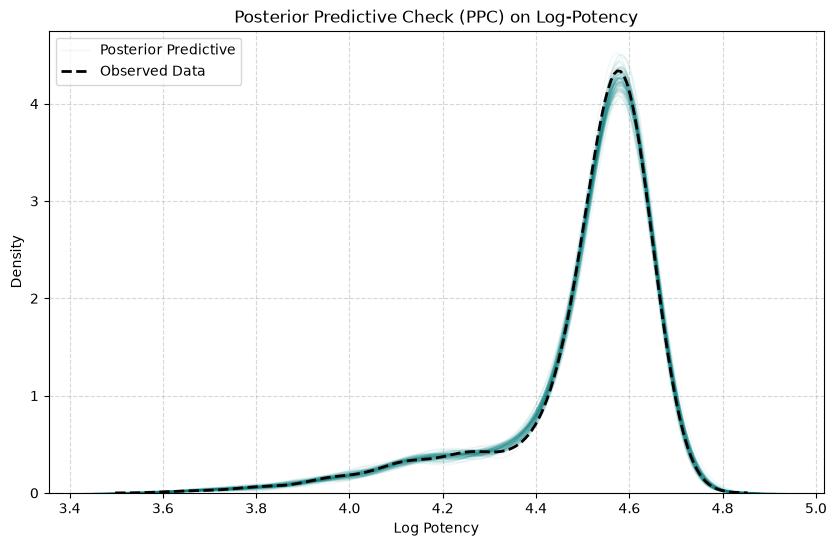

In [18]:
with model:
    ppc = pm.sample_posterior_predictive(
        idata,
        var_names=["y"]
    )

# Extract simulated predictions and actual observed values
y_pred = ppc.posterior_predictive["y"].values
y_obs = df["log_potency"].values

# Reshape predictions to 2D (draws, observations)
y_pred_flat = y_pred.reshape(-1, y_pred.shape[-1])

plt.figure(figsize=(10, 6))

# Plot a subset of posterior predictive draws to show the uncertainty
for i in range(min(100, len(y_pred_flat))):
    sns.kdeplot(y_pred_flat[i], color="teal", alpha=0.06, linewidth=1, label="Posterior Predictive" if i == 0 else "")

# Plot the observed data distribution
sns.kdeplot(y_obs, color="black", linewidth=2, label="Observed Data", linestyle="--")

plt.title("Posterior Predictive Check (PPC) on Log-Potency")
plt.xlabel("Log Potency")
plt.ylabel("Density")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

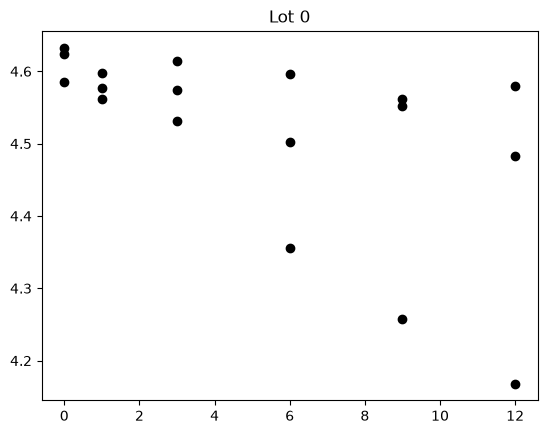

In [19]:
lot = 0

mask = (
    df.lot_idx == lot
)

plt.scatter(
    df.loc[mask,"time_months"],
    df.loc[mask,"log_potency"],
    color="black"
)

plt.title(
    f"Lot {lot}"
)

plt.show()

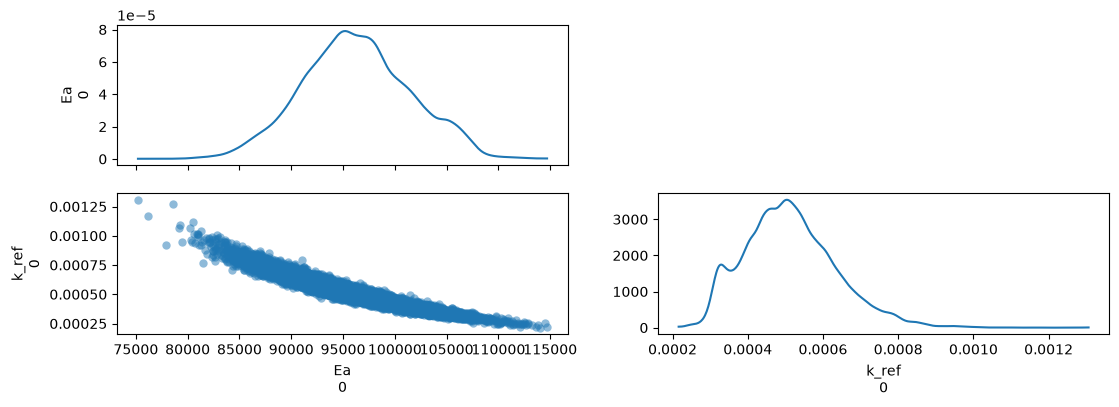

In [20]:
# Select a specific lot (e.g., Lot 0) to avoid generating subplots for all 24 lots
az.plot_pair(
    idata,
    var_names=["Ea", "k_ref"],
    coords={"lot": [0]}
)

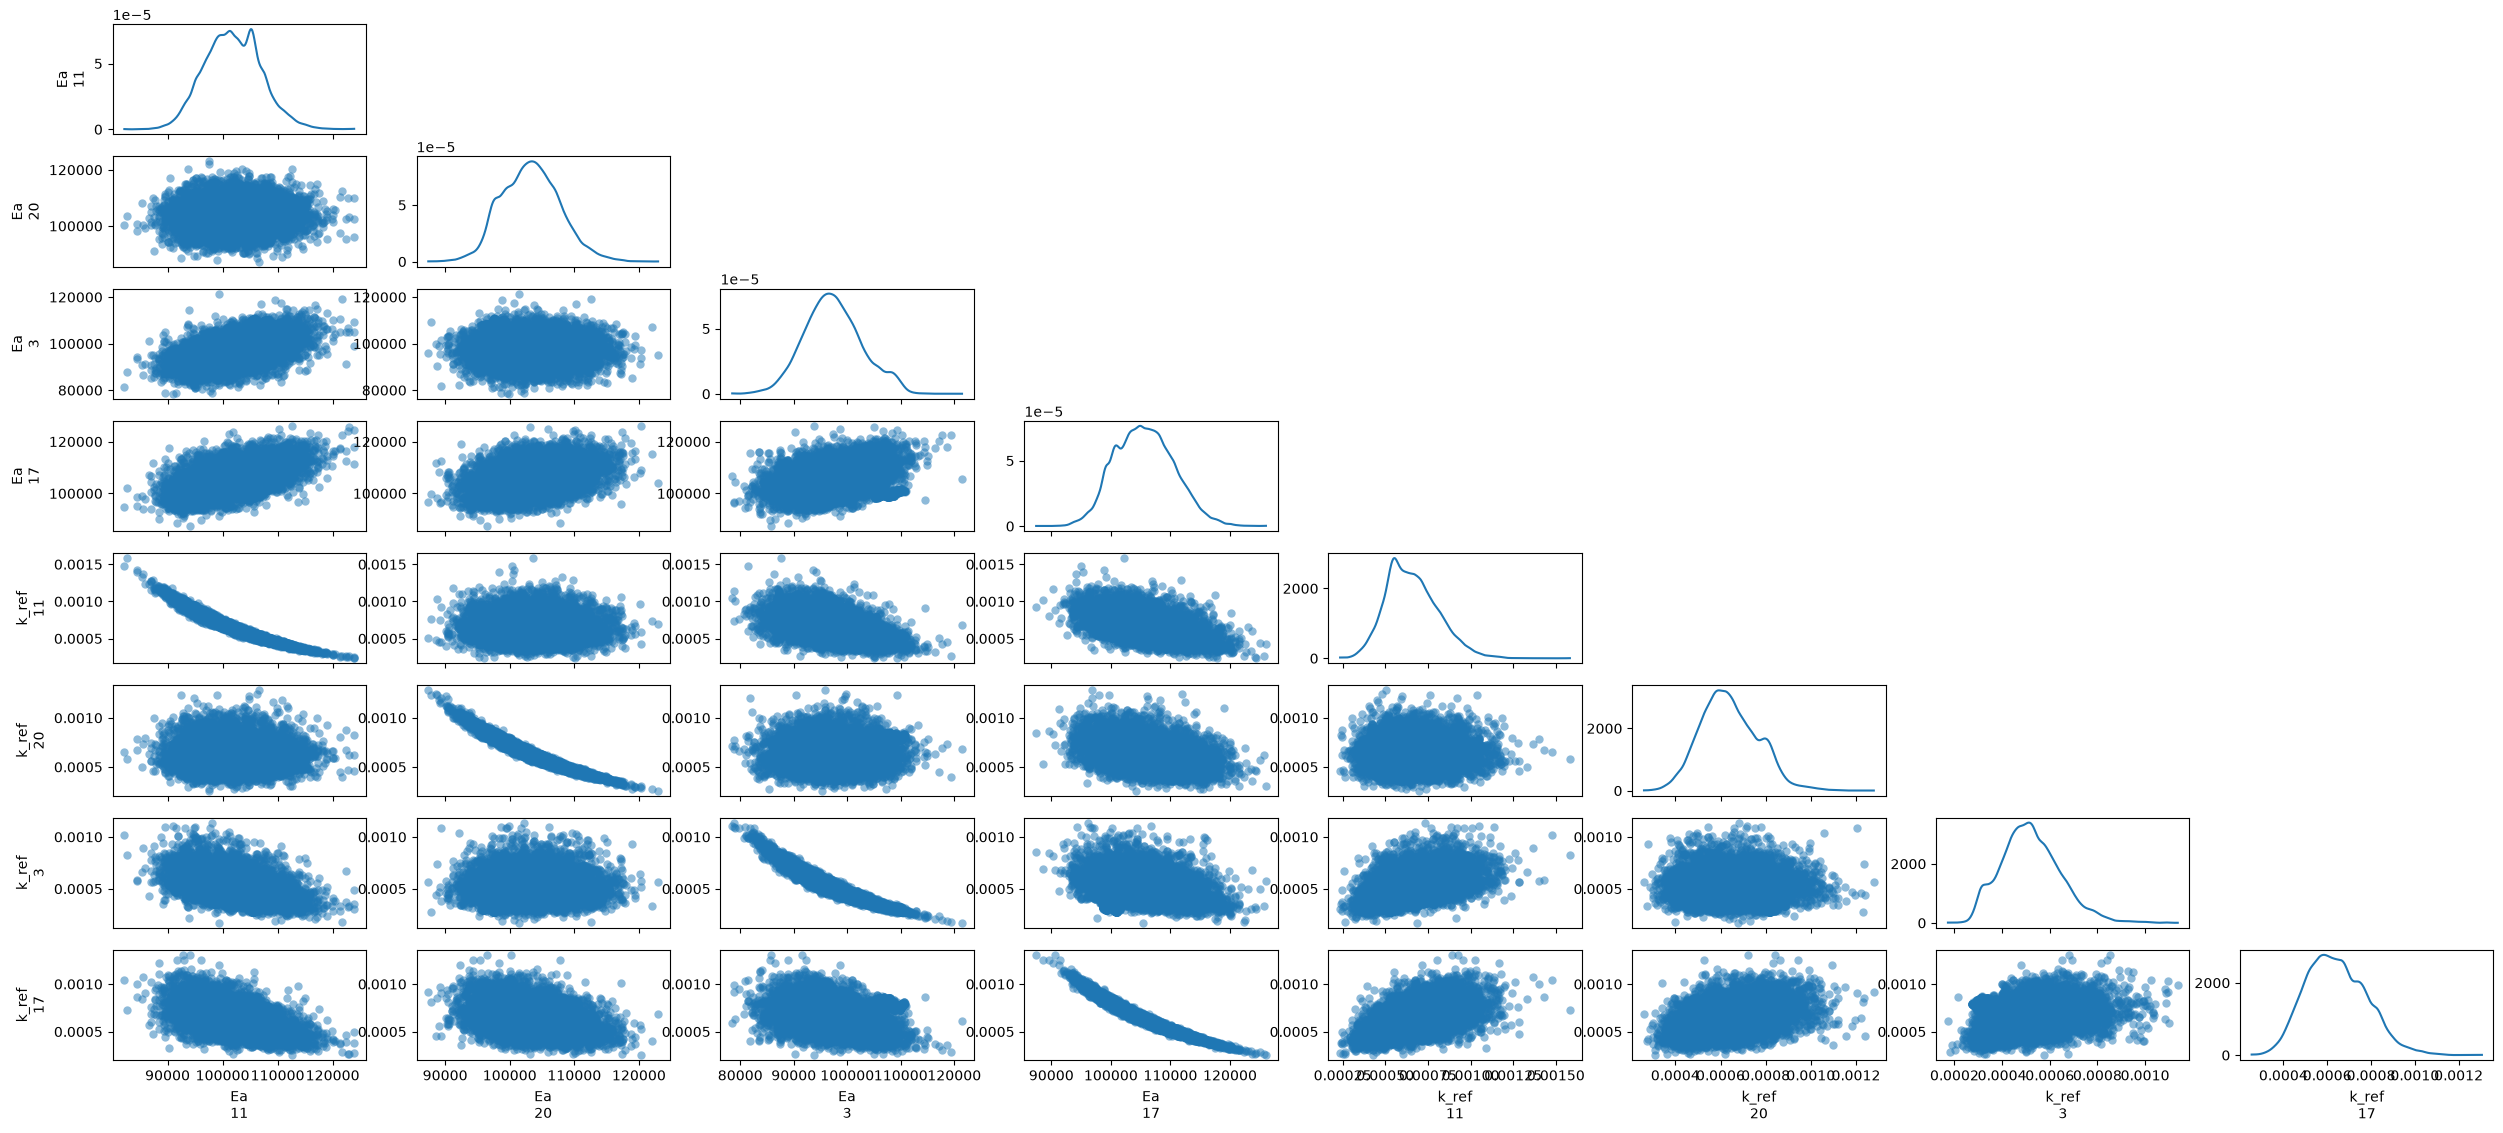

In [21]:
import arviz as az
import numpy as np

# Pick 4 random lots
lots_to_plot = np.random.choice(24, 4, replace=False)

# Temporarily raise maximum subplots
az.rcParams["plot.max_subplots"] = 100

# Under the new ArviZ v1.x plotting backend, we use 'marginal' instead of 'marginals'
# and we do not pass 'kind' or 'divergences' directly as standard keyword arguments.
az.plot_pair(
    idata,
    var_names=["Ea", "k_ref"],
    coords={"lot": lots_to_plot},
    marginal=True
)

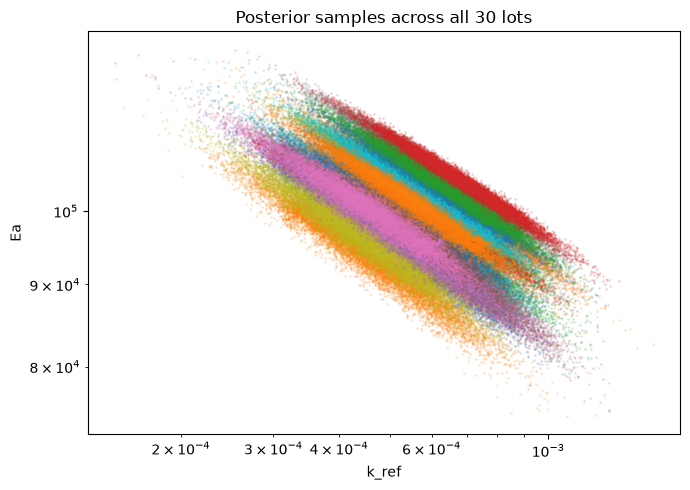

In [23]:
import numpy as np
import matplotlib.pyplot as plt

k_ref = idata.posterior["k_ref"].stack(sample=("chain", "draw")).values   # (24, N)
Ea    = idata.posterior["Ea"].stack(sample=("chain", "draw")).values      # (24, N)

fig, ax = plt.subplots(figsize=(7, 5))
for lot in range(k_ref.shape[0]):
    ax.scatter(k_ref[lot], Ea[lot], s=1, alpha=0.15)
ax.set_xlabel("k_ref")
ax.set_ylabel("Ea")
ax.set_yscale("log")
ax.set_xscale("log")
ax.set_title("Posterior samples across all 30 lots")
plt.tight_layout()

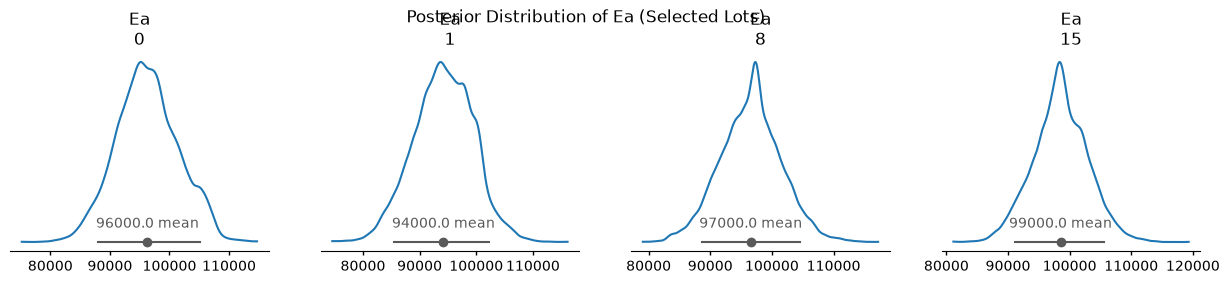

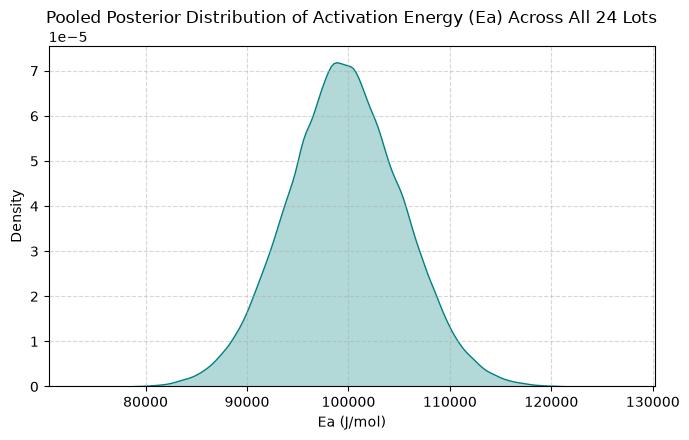

In [24]:
import arviz_plots as azp
import matplotlib.pyplot as plt

# Option 1: Plotting only specific lots of interest (e.g., Lots 0 and 1) to keep the grid clean
azp.plot_dist(idata, var_names=["Ea"], coords={"lot": [0, 1, 8, 15]})
plt.suptitle("Posterior Distribution of Ea (Selected Lots)", y=1.05)
plt.show()

# Option 2: Pool all 24 lots together into a single combined distribution plot
# We stack the chains, draws, and lots into a single combined dimension
Ea_pooled = idata.posterior["Ea"].stack(pooled_draws=("chain", "draw", "lot"))

plt.figure(figsize=(7, 4.5))
sns.kdeplot(Ea_pooled.values, color="teal", fill=True, alpha=0.3)
plt.title("Pooled Posterior Distribution of Activation Energy (Ea) Across All 24 Lots")
plt.xlabel("Ea (J/mol)")
plt.ylabel("Density")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [25]:
import os
import matplotlib.pyplot as plt

def save_fig(path, dpi=150):
    """Save the current matplotlib figure to path, then close it."""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    fig = plt.gcf()
    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    plt.close(fig)

In [26]:
az.plot_pair(idata, var_names=["Ea", "k_ref"],
             coords={"lot": [0, 1, 8, 15]})
save_fig("run/pair_Ea_kref.png")

az.plot_energy(idata)
save_fig("run/energy.png")

In [27]:
import os
import sys

# Ensure both h5netcdf and its core engine h5py are installed
try:
    import h5py
    import h5netcdf
except ImportError:
    print("Installing missing backend engine dependencies...")
    !{sys.executable} -m pip install h5py h5netcdf

import arviz as az

# Safely ensure path exists or fall back to saving/loading from current working directory
nc_path = "idata.nc"
if not os.path.exists(nc_path):
    # Fallback in case it was saved in the root directory
    if os.path.exists("idata.nc"):
        nc_path = "idata.nc"
    else:
        # If not saved at all yet, let's create directory and save current in-memory idata
        os.makedirs("run", exist_ok=True)
        idata.to_netcdf("run/idata.nc", engine="h5netcdf")
        nc_path = "run/idata.nc"

# Explicitly pass engine="h5netcdf" to bypass guesswork failures
idata = az.from_netcdf(nc_path, engine="h5netcdf")
print("Loaded groups:", idata.groups)

Loaded groups: ('/', '/posterior', '/sample_stats', '/warmup_posterior', '/warmup_sample_stats')


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
Ea[0],9.63e+04,5.23e+03,88000,110000,169,68,1.02,420,200
Ea[1],9.42e+04,5.27e+03,86000,100000,764,3702,1.01,190,46
Ea[2],9.80e+04,4.98e+03,90000,110000,5275,6531,1.01,68,65
Ea[3],9.74e+04,5.40e+03,89000,110000,117,37,1.03,540,460
Ea[4],9.61e+04,4.96e+03,88000,100000,211,242,1.02,350,48
Ea[5],9.58e+04,4.77e+03,88000,100000,4163,4571,1.01,73,58
Ea[6],9.64e+04,4.82e+03,89000,100000,1748,5867,1.01,110,46
Ea[7],9.62e+04,4.76e+03,89000,100000,4619,5766,1.01,70,52
Ea[8],9.66e+04,4.97e+03,89000,100000,4936,5965,1.02,71,77
Ea[9],9.96e+04,4.49e+03,93000,110000,5883,4808,1.01,58,53


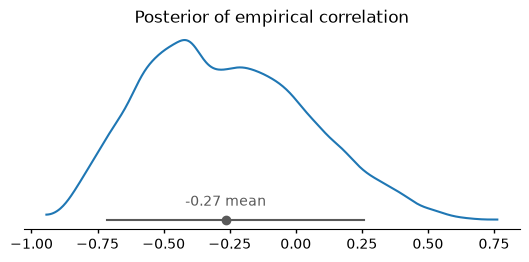

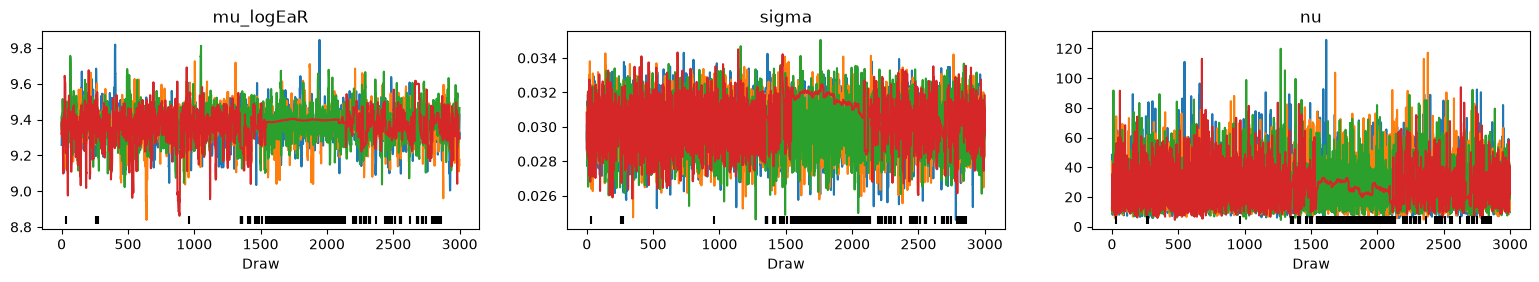

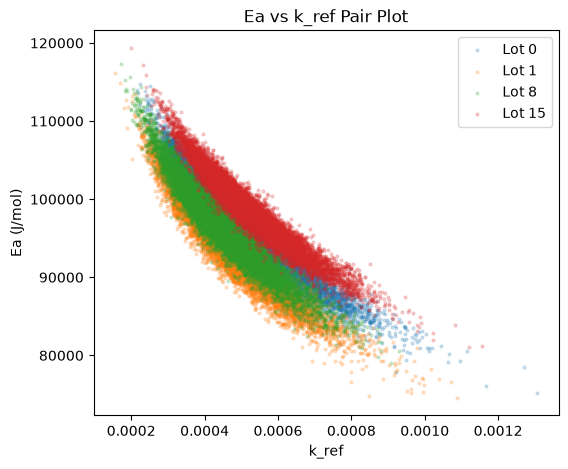


Mean Ea per lot:
 [ 96302.14202751  94213.95723821  98018.83007766  97423.16237202
  96128.37098425  95764.17051231  96437.67847069  96153.69460087
  96567.89974113  99639.44182426  99893.65016062 101880.2259614
 100567.14133935 100514.00924002  97866.43953449  98520.68669189
  99887.00472704 105664.24831083 103262.70472287 102960.09345285
 103272.67731284 101360.51740268 103544.07560614 104529.48107202]


In [30]:
import arviz as az
import arviz_plots as azp
import matplotlib.pyplot as plt

# 1. Parameter Summary (still supported directly on az)
display(az.summary(idata, var_names=["Ea", "k_ref", "t90_25"]))

# 2. Plot Posterior in ArviZ v1.x by passing idata and specifying var_names
az.plot_dist(idata, var_names=["corr_k_Ea_empirical"])
plt.title("Posterior of empirical correlation")
plt.show()

# 3. Plot Trace (corrected to plot_trace)
azp.plot_trace(idata, var_names=["mu_logEaR", "sigma", "nu"])
plt.show()

# 4. Custom Pair Plot using matplotlib
k_ref_vals = idata.posterior.data_vars["k_ref"].sel(lot=[0, 1, 8, 15]).values
Ea_vals = idata.posterior.data_vars["Ea"].sel(lot=[0, 1, 8, 15]).values

fig, ax = plt.subplots(figsize=(6, 5))
for i, lot_id in enumerate([0, 1, 8, 15]):
    ax.scatter(k_ref_vals[:, :, i].flatten(), Ea_vals[:, :, i].flatten(), alpha=0.2, label=f"Lot {lot_id}", s=4)
ax.set_xlabel("k_ref")
ax.set_ylabel("Ea (J/mol)")
ax.set_title("Ea vs k_ref Pair Plot")
ax.legend()
plt.show()

# Access posterior values directly for further calculations
mean_ea_values = idata.posterior.data_vars["Ea"].mean(("chain", "draw")).values
print("\nMean Ea per lot:\n", mean_ea_values)

Sampling ... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 0:00:00 / 0:00:08

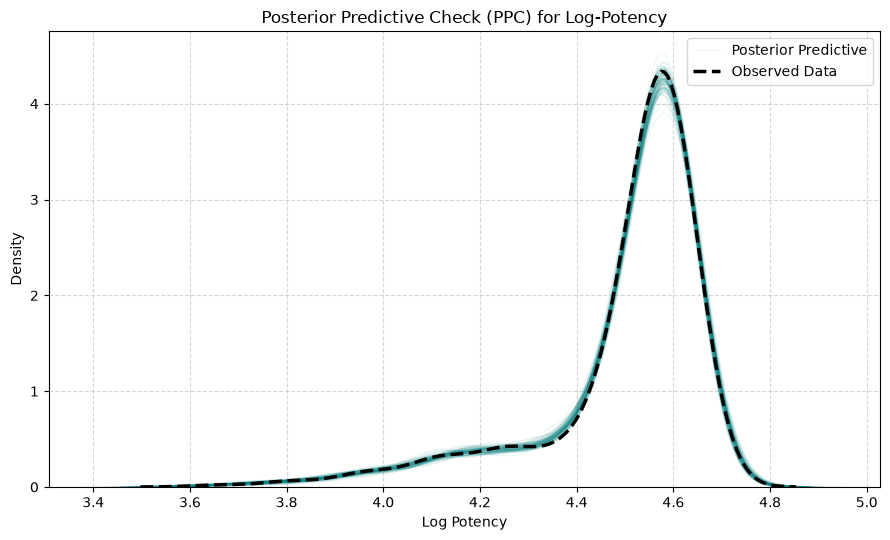

In [31]:
import pymc as pm
import matplotlib.pyplot as plt
import seaborn as sns

# Generate posterior predictive distributions using PyMC
with model:
    ppc_idata = pm.sample_posterior_predictive(idata, extend_inferencedata=True)

# Extract simulated predictions and original observed targets
y_pred = ppc_idata.posterior_predictive["y"].values
y_obs = df["log_potency"].values

# Reshape predictions to 2D (draws * chains, observations)
y_pred_flat = y_pred.reshape(-1, y_pred.shape[-1])

# Set up the visualization
plt.figure(figsize=(9, 5.5))

# Draw a sample of predictive runs to illustrate distribution uncertainty
for i in range(min(100, len(y_pred_flat))):
    sns.kdeplot(y_pred_flat[i], color="teal", alpha=0.06, linewidth=1, label="Posterior Predictive" if i == 0 else "")

# Draw the physical observed data trend
sns.kdeplot(y_obs, color="black", linewidth=2.5, label="Observed Data", linestyle="--")

plt.title("Posterior Predictive Check (PPC) for Log-Potency")
plt.xlabel("Log Potency")
plt.ylabel("Density")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

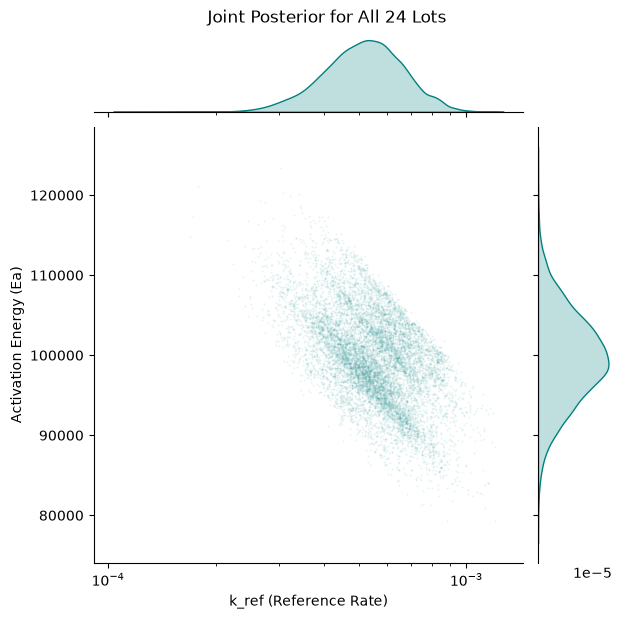

In [32]:
import arviz as az
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Extract and stack the draws for Ea and k_ref across all 24 lots
# This collapses the lot dimension so we can plot them all together on a single axes pair
posterior = idata.posterior

# We will sample or plot a subset of points from each lot to create a clear overlay
Ea_stacked = posterior["Ea"].stack(sample=("chain", "draw", "lot")).values
k_ref_stacked = posterior["k_ref"].stack(sample=("chain", "draw", "lot")).values

# Construct a DataFrame for plotting
plot_df = pd.DataFrame({
    "Activation Energy (Ea)": Ea_stacked,
    "k_ref (Reference Rate)": k_ref_stacked
})

# Sample a subset of points for better visibility if the density is too high
sampled_df = plot_df.sample(n=10000, random_state=123) if len(plot_df) > 10000 else plot_df

# Create a joint distribution pair plot using seaborn on the extracted posterior
g = sns.JointGrid(data=sampled_df, x="k_ref (Reference Rate)", y="Activation Energy (Ea)", height=6)
g.plot_joint(sns.scatterplot, alpha=0.1, color="teal", s=2)
g.plot_marginals(sns.kdeplot, fill=True, color="teal")

g.ax_joint.set_xscale("log")
g.fig.suptitle("Joint Posterior for All 24 Lots", y=1.02, fontsize=12)
plt.show()

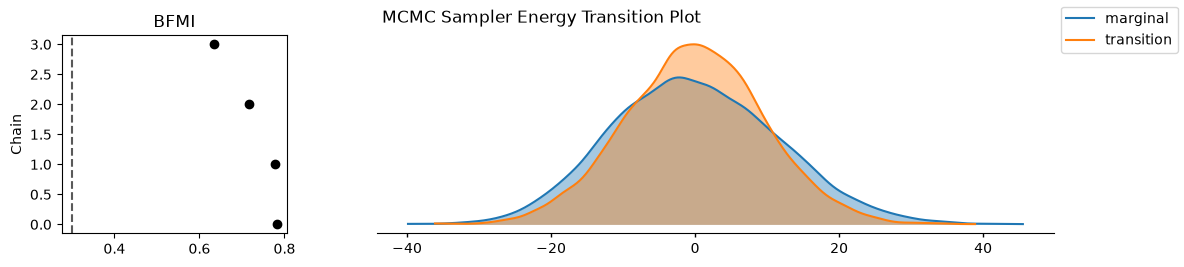

In [33]:
import arviz as az
import matplotlib.pyplot as plt

# Create an energy plot utilizing ArviZ's built-in layout management
plot_coll = az.plot_energy(idata)

# Adjust title and display safely
plt.suptitle("MCMC Sampler Energy Transition Plot", y=0.98)
plt.show()

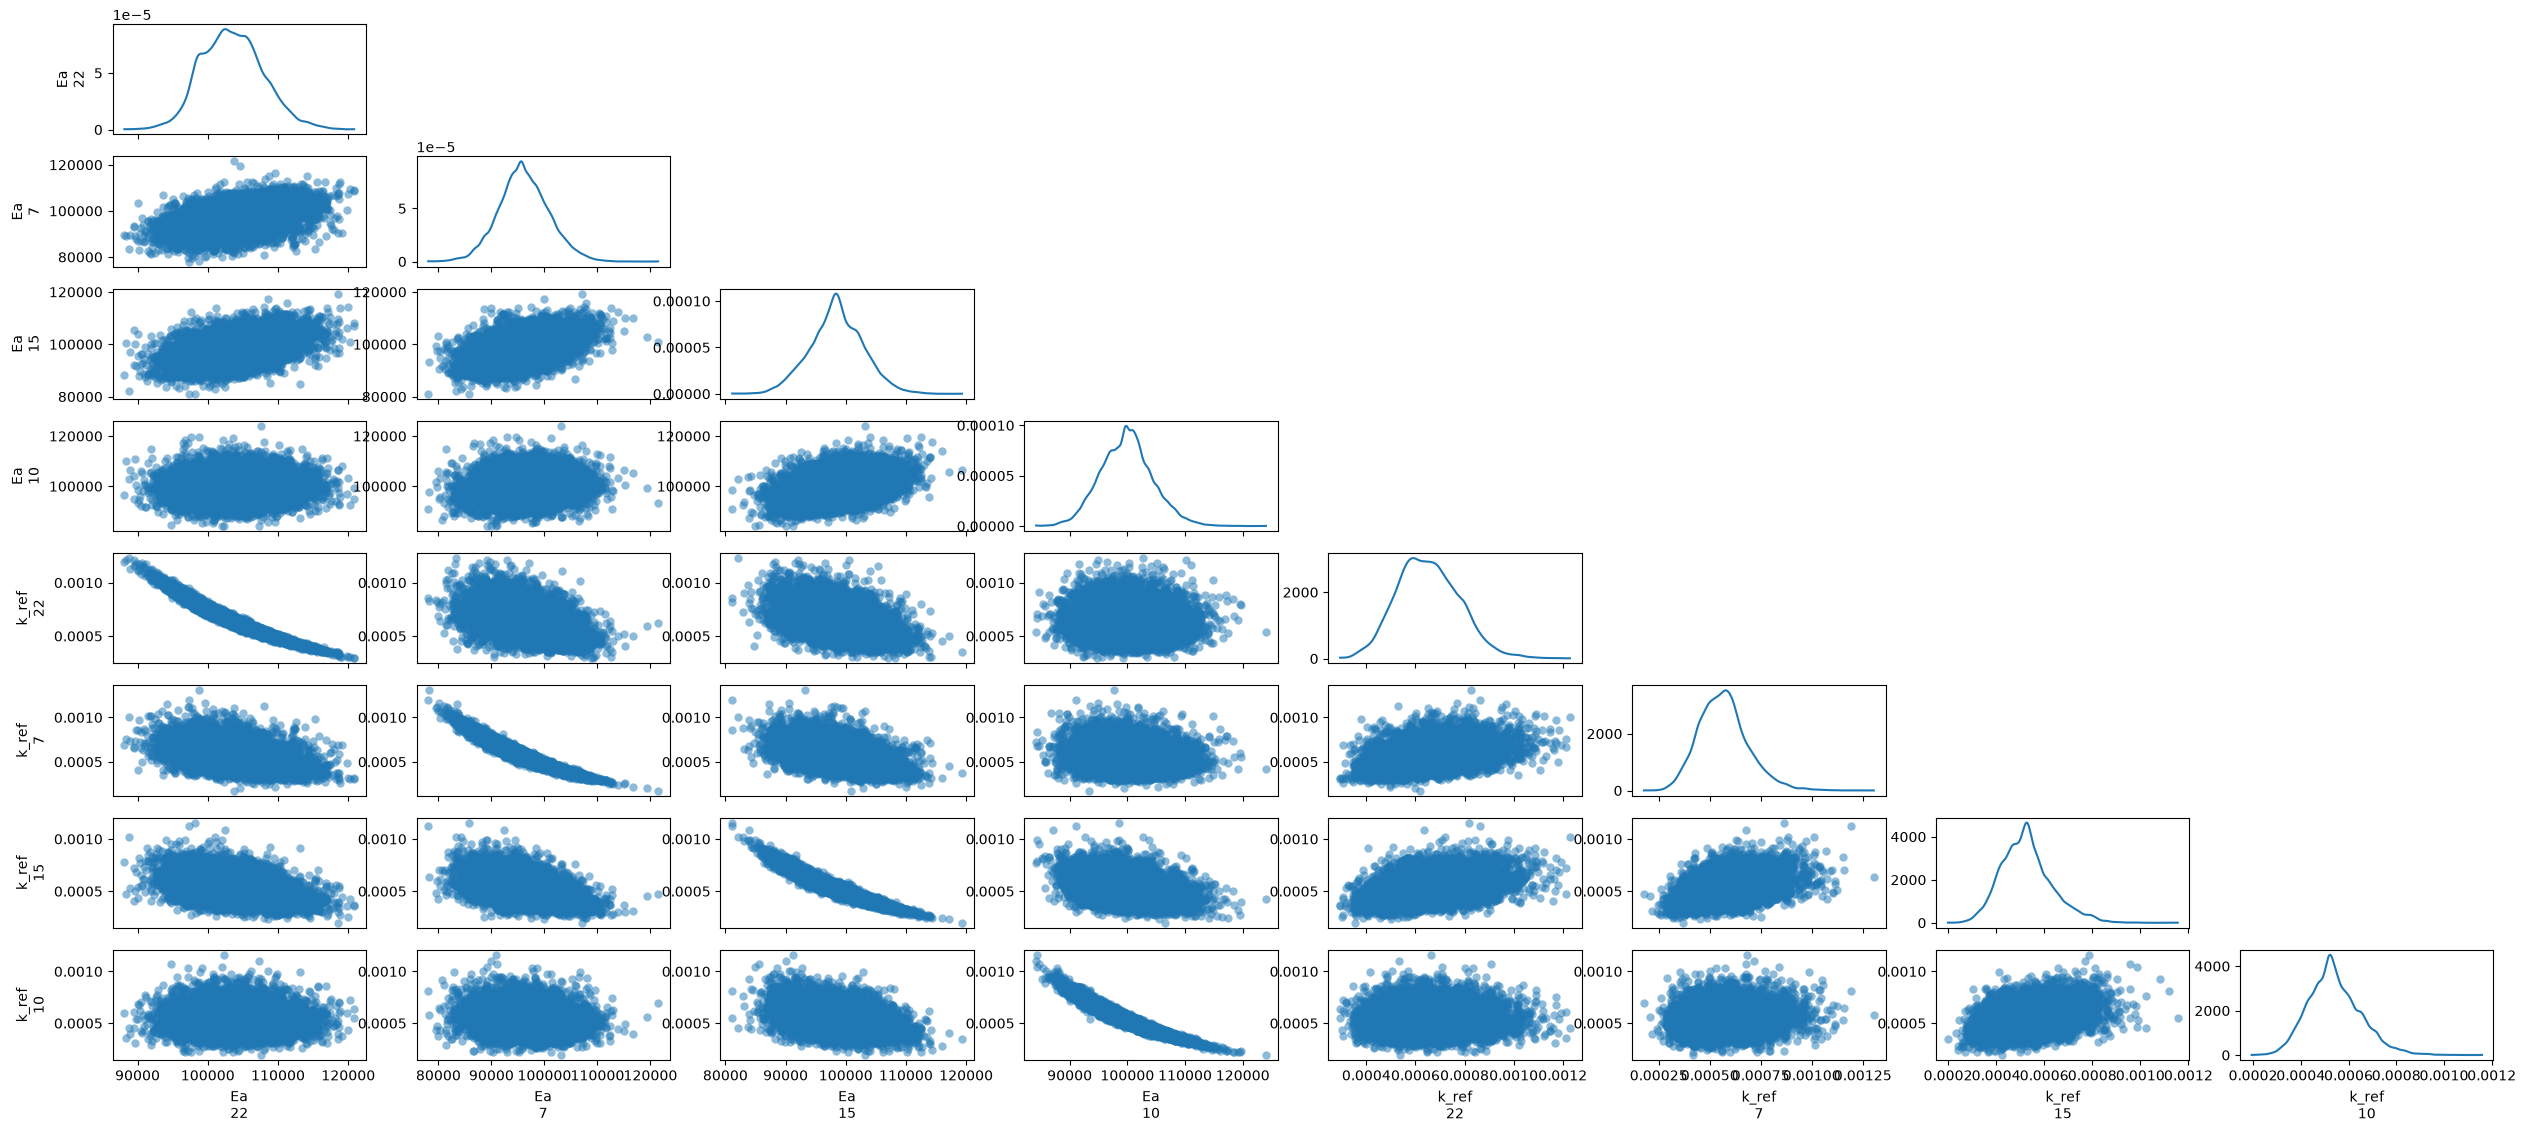

In [34]:
import arviz as az
import numpy as np

# Pick 4 random lots
lots_to_plot = np.random.choice(24, 4, replace=False)

# Temporarily raise maximum subplots
az.rcParams["plot.max_subplots"] = 100

# Under the new ArviZ v1.x plotting backend, we use 'marginal' instead of 'marginals'
# and we do not pass 'kind' or 'divergences' directly as standard keyword arguments.
az.plot_pair(
    idata,
    var_names=["Ea", "k_ref"],
    coords={"lot": lots_to_plot},
    marginal=True
)

In [36]:
import arviz as az
trace = az.from_netcdf("idata.nc")   # Or "idata.nc"

In [37]:
import arviz as az

# 1. Summary table (contains r_hat, ess_bulk, ess_tail, etc.)
summary = az.summary(trace)
print(summary)

# 2. Extract specific diagnostics
# Rhat and ESS (already included in the summary, can also be extracted separately)
rhat = az.rhat(trace)          # Rhat for each parameter
ess_bulk = az.ess(trace, method="bulk")
ess_tail = az.ess(trace, method="tail")

# 3. Divergences (stored in sample_stats)
divergences = trace.sample_stats["diverging"].values.sum()
print(f"Divergences: {divergences}")

# 4. BFMI (E-BFMI, Energy Bayesian Fraction of Missing Information)
bfmi = az.bfmi(trace)
print(f"BFMI per chain: {bfmi}")

# 5. Chain sizes (directly view dimensions)
print(f"Chains: {trace.posterior.dims['chain']}, Draws: {trace.posterior.dims['draw']}")

                         mean        sd eti89_lb eti89_ub ess_bulk ess_tail r_hat mcse_mean  mcse_sd
alpha0                 4.5996    0.0058      4.6      4.6     4633     4574  1.00   8.4e-05    6e-05
alpha_raw[0]            -0.05     0.376    -0.66     0.53     1026     1032  1.00     0.012   0.0038
alpha_raw[1]            1.439     0.411     0.81      2.1     7154     6531  1.01    0.0048   0.0042
alpha_raw[2]             -1.6       0.5     -2.6    -0.88       74       32  1.04     0.072    0.077
alpha_raw[3]             -0.4     0.376    -0.99      0.2      955     2328  1.01     0.012   0.0034
alpha_raw[4]             0.93      0.41      0.3      1.6     2588     1625  1.01    0.0079   0.0051
alpha_raw[5]             1.78     0.461      1.1      2.5      474      393  1.01     0.022   0.0042
alpha_raw[6]            0.119     0.366    -0.47      0.7     8248     7130  1.01     0.004   0.0047
alpha_raw[7]             0.47     0.376    -0.13      1.1      593     2855  1.01     0.016

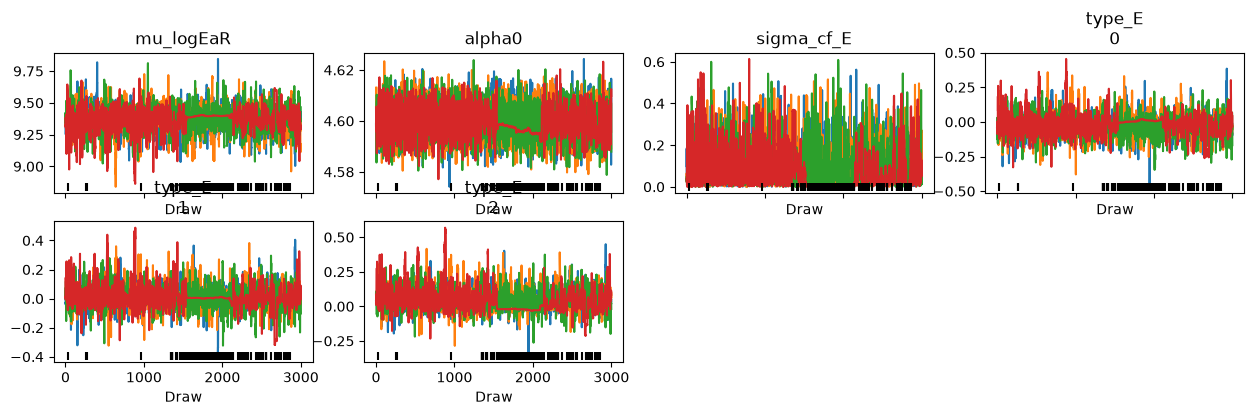

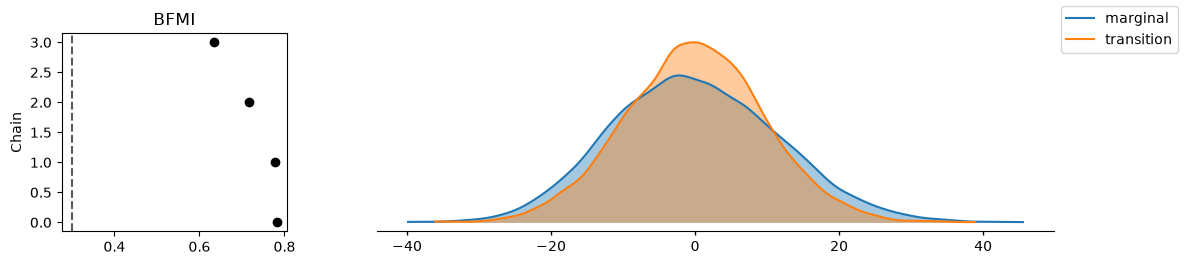

In [38]:
az.plot_trace(trace, var_names=["mu_logEaR", "alpha0", "sigma_cf_E", "type_E"])
az.plot_energy(trace)

In [39]:
import pymc as pm

# Ensure model is still in memory, or re-establish the model context
pm.compute_log_likelihood(trace, model=model)

Computing ... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 0:00:00

<xarray.DataTree>
Group: /
├── Group: /posterior
│       Dimensions:              (chain: 4, draw: 3000, lot: 24, type: 3, coform: 2)
│       Coordinates:
│         * chain                (chain) int64 32B 0 1 2 3
│         * draw                 (draw) int64 24kB 0 1 2 3 4 ... 2996 2997 2998 2999
│         * lot                  (lot) int64 192B 0 1 2 3 4 5 6 ... 17 18 19 20 21 22 23
│         * type                 (type) int64 24B 0 1 2
│         * coform               (coform) int64 16B 0 1
│       Data variables: (12/30)
│           alpha0               (chain, draw) float64 96kB 4.599 4.596 ... 4.612 4.61
│           alpha_raw            (chain, draw, lot) float64 2MB -0.3168 1.597 ... -2.711
│           type_k_raw           (chain, draw, type) float64 288kB -0.2067 ... -1.386
│           type_E_raw           (chain, draw, type) float64 288kB -0.8991 ... 0.7351
│           coform_k_raw         (chain, draw, coform) float64 192kB -3.191 ... -2.381
│           coform_E_raw         (chain, draw, coform) float64 192kB 0.9814 ... 0.7818
│           ...                   ...
│           logk                 (chain, draw, lot) float64 2MB -7.468 -7.631 ... -7.424
│           logEaR               (chain, draw, lot) float64 2MB 9.321 9.29 ... 9.447
│           t90_25               (chain, draw, lot) float64 2MB 12.46 15.96 ... 8.324
│           Ea                   (chain, draw, lot) float64 2MB 9.291e+04 ... 1.053e+05
│           k_ref                (chain, draw, lot) float64 2MB 0.0005711 ... 0.0005967
│           corr_k_Ea_empirical  (chain, draw) float64 96kB -0.02019 -0.197 ... -0.5642
│       Attributes:
│           created_at:                 2026-11-18T18:04:04.128555+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_library_language:  Python
│           sample_dims:                ['chain', 'draw']
├── Group: /sample_stats
│       Dimensions:                   (chain: 4, draw: 3000)
│       Coordinates:
│         * chain                     (chain) int64 32B 0 1 2 3
│         * draw                      (draw) int64 24kB 0 1 2 3 ... 2996 2997 2998 2999
│       Data variables: (12/20)
│           depth                     (chain, draw) uint64 96kB ...
│           maxdepth_reached          (chain, draw) bool 12kB ...
│           step_size                 (chain, draw) float64 96kB ...
│           transformation_update_id  (chain, draw) int64 96kB ...
│           step_size_bar             (chain, draw) float64 96kB ...
│           mean_tree_accept          (chain, draw) float64 96kB ...
│           ...                        ...
│           fisher_distance           (chain, draw) float64 96kB ...
│           transformation_index      (chain, draw) int64 96kB ...
│           diverging                 (chain, draw) bool 12kB False False ... False
│           divergence_draw           (chain, draw) uint64 96kB ...
│           divergence_message        (chain, draw) <U47 2MB ...
│           divergence_energy_error   (chain, draw) float64 96kB ...
│       Attributes:
│           created_at:                  2026-11-18T18:04:04.236243+00:00
│           creation_library:            ArviZ
│           creation_library_version:    1.3.1
│           creation_library_language:   Python
│           sample_dims:                 ['chain', 'draw']
│           inference_library:           nutpie
│           inference_library_version:   0.16.11
│           inference_library_settings:  {"sampler": "nuts", "adaptation": "diag", "s...
├── Group: /warmup_posterior
│       Dimensions:              (chain: 4, draw: 1500, lot: 24, type: 3, coform: 2)
│       Coordinates:
│         * chain                (chain) int64 32B 0 1 2 3
│         * draw                 (draw) int64 12kB 0 1 2 3 4 ... 1496 1497 1498 1499
│         * lot                  (lot) int64 192B 0 1 2 3 4 5 6 ... 17 18 19 20 21 22 23
│         * type                 (type) int64 24B 0 1 2
│         * coform       

In [40]:
import arviz_stats as azs

loo_result = azs.loo(trace)
print(loo_result)

# Check Pareto k
pareto_k = loo_result.pareto_k
print(f"Pareto k > 0.7: {(pareto_k > 0.7).sum().item()}")

Computed from 12000 posterior samples and 432 observations log-likelihood matrix.

         Estimate       SE
elpd_loo   856.48    14.81
p_loo       44.95        -
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)      432  100.0%
   (0.70, 1]   (bad)         0    0.0%
    (1, Inf)   (very bad)    0    0.0%

Pareto k > 0.7: 0


In [41]:
loo_result = az.loo(trace)
print(loo_result)
# Check pareto_k similarly

Computed from 12000 posterior samples and 432 observations log-likelihood matrix.

         Estimate       SE
elpd_loo   856.48    14.81
p_loo       44.95        -
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)      432  100.0%
   (0.70, 1]   (bad)         0    0.0%
    (1, Inf)   (very bad)    0    0.0%



In [42]:
loo_result = az.loo(trace, moment_match=True, model=model)
k = loo_result.pareto_k.values
bad_idx = np.where(k > 0.7)[0]
print("Observation index:", bad_idx)
print("Observed value:", y_obs[bad_idx])

Observation index: []
Observed value: []


C:\WinPython\python\Lib\site-packages\arviz_stats\loo\loo_moment_match.py:277: UserWarning: No Pareto k values exceed the threshold. Returning original LOO data.
  warnings.warn("No Pareto k values exceed the threshold. Returning original LOO data.")


In [45]:
T_REF   = 278.15          # must equal the model's value — verify from the modelling cell
LN_10_9 = np.log(10.0 / 9.0)

def t90_samples(idata, temp_C):
    # Access variables directly from the dataset instead of slicing coordinates
    logk   = idata.posterior["logk"]
    logEaR = idata.posterior["logEaR"]
    T_K    = temp_C + 273.15
    log_kT = logk + np.exp(logEaR) * (1.0 / T_REF - 1.0 / T_K)
    return LN_10_9 / np.exp(log_kT)

diff = (t90_samples(idata, 25).mean(dim=("chain", "draw")).values
        - idata.posterior["t90_25"].mean(dim=("chain", "draw")).values)
print("max |diff| =", np.max(np.abs(diff)))
assert np.allclose(diff, 0.0, atol=1e-6)
print("✅ t90_samples(25) == t90_25 matches perfectly")

max |diff| = 5.329070518200751e-15
✅ t90_samples(25) == t90_25 matches perfectly


In [50]:
import numpy as np
import pandas as pd
import xarray as xr
import arviz as az


def _as_single_dataarray(obj):
    """Return a DataArray; unwrap a single-variable Dataset (ArviZ sometimes returns one)."""
    if isinstance(obj, xr.DataArray):
        return obj
    if isinstance(obj, xr.Dataset):
        names = list(obj.data_vars)
        if len(names) != 1:
            raise ValueError(
                f"Expected a single data variable, got {names}. "
                f"Select one (e.g. ds[name]) before calling."
            )
        return obj[names[0]]
    raise TypeError(f"Cannot coerce {type(obj).__name__} to a DataArray")


def _extract_hdi_bounds(hdi_obj, sample_da):
    """Split az.hdi output into (lower, upper) DataArrays over `sample_da`'s dims."""
    hdi_da = _as_single_dataarray(hdi_obj)

    extra_dims = [d for d in hdi_da.dims if d not in sample_da.dims]
    if not extra_dims:
        raise ValueError(
            f"az.hdi output has no new bound dimension: "
            f"dims={tuple(hdi_da.dims)}, input dims={tuple(sample_da.dims)}"
        )
    bound_dim = extra_dims[0]
    labels = list(hdi_da[bound_dim].values) if bound_dim in hdi_da.coords else []

    def pick(name, pos):
        if name in labels:
            return hdi_da.sel({bound_dim: name})
        return hdi_da.isel({bound_dim: pos})

    return pick("lower", 0), pick("higher", 1)


def shelf_life_table(idata, temps_C=(5, 25, 37), hdi_prob=0.95):
    rows   = []
    lo_col = f"hdi_{int(hdi_prob * 100)}_low"
    hi_col = f"hdi_{int(hdi_prob * 100)}_high"

    for T_C in temps_C:
        # Normalize to a DataArray no matter what t90_samples returns
        s = _as_single_dataarray(t90_samples(idata, T_C))   # dims (chain, draw, lot)

        mean   = np.asarray(s.mean(dim=("chain", "draw")))
        median = np.asarray(s.median(dim=("chain", "draw")))

        # ArviZ renamed this kwarg across versions; try both.
        try:
            hdi_obj = az.hdi(s, prob=hdi_prob)
        except TypeError:
            hdi_obj = az.hdi(s, hdi_prob=hdi_prob)

        low_da, high_da = _extract_hdi_bounds(hdi_obj, s)
        hdi_low  = np.asarray(low_da)
        hdi_high = np.asarray(high_da)

        lots = (s["lot"].values if "lot" in s.coords
                else np.arange(s.sizes["lot"]))

        for i, lot in enumerate(lots):
            rows.append({
                "lot":        int(lot),
                "temp_C":     T_C,
                "mean_t90":   float(mean[i]),
                "median_t90": float(median[i]),
                lo_col:       float(hdi_low[i]),
                hi_col:       float(hdi_high[i]),
            })

    return (pd.DataFrame(rows)
              .sort_values(["lot", "temp_C"])
              .reset_index(drop=True))


if __name__ == "__main__":
    table = shelf_life_table(idata, temps_C=(5, 25, 37), hdi_prob=0.95)
    print(table.to_string(index=False))
    table.to_csv("t90_summary.csv", index=False)

 lot  temp_C   mean_t90  median_t90  hdi_95_low  hdi_95_high
   0       5 217.660360  209.259440  134.116902   335.265196
   0      25  13.009560   12.898467   10.762645    15.663116
   0      37   2.884482    2.877852    2.576190     3.198725
   1       5 242.397246  235.557484  136.756458   358.449053
   1      25  15.393644   15.281867   12.499266    18.687945
   1      37   3.526270    3.514053    3.069895     4.005479
   2       5 189.297561  185.272200  109.842957   275.303737
   2      25  10.789615   10.766706    8.919680    12.637844
   2      37   2.329910    2.326189    2.119069     2.542448
   3       5 214.325595  205.566775  128.771000   336.469597
   3      25  12.383701   12.283806   10.227183    14.903718
   3      37   2.698163    2.690424    2.421826     2.968839
   4       5 205.363317  198.875434  124.123810   294.869963
   4      25  12.369689   12.307069   10.226204    14.541408
   4      37   2.751274    2.744080    2.469192     3.039805
   5       5 196.232683 

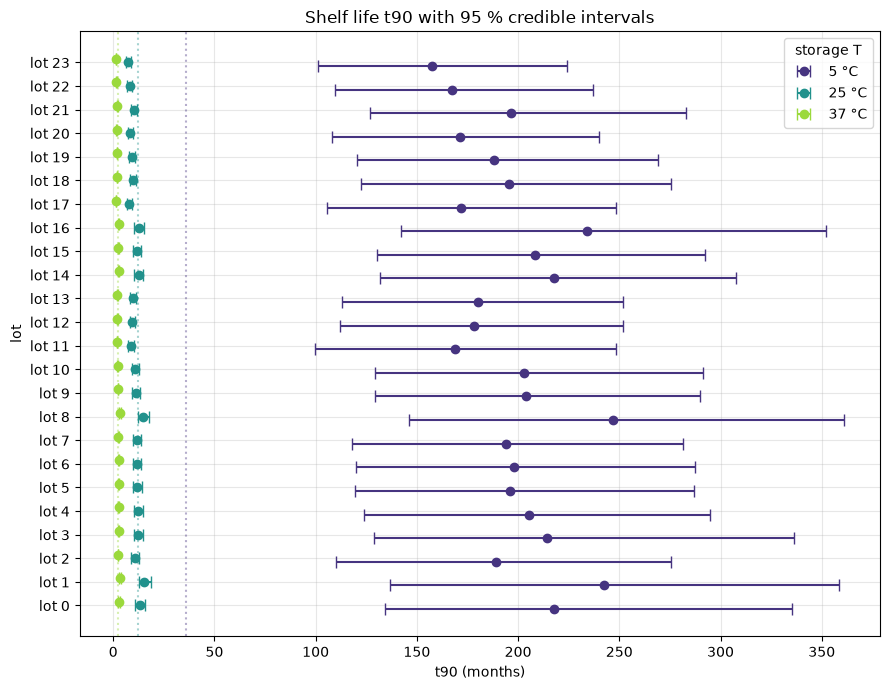

In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the calculated shelf-life table from the saved CSV
table = pd.read_csv("t90_summary.csv")

temps_C = (5, 25, 37)
fig, ax = plt.subplots(figsize=(9, 7))
colors = plt.cm.viridis(np.linspace(0.15, 0.85, len(temps_C)))
jitter = np.linspace(-0.15, 0.15, len(temps_C))

for color, dT, T_C in zip(colors, jitter, temps_C):
    sub = table[table["temp_C"] == T_C]
    y   = sub["lot"].values + dT
    m   = sub["mean_t90"].values
    lo  = sub["hdi_95_low"].values
    hi  = sub["hdi_95_high"].values
    ax.errorbar(m, y, xerr=[m - lo, hi - m], fmt="o",
                color=color, capsize=4, label=f"{T_C} °C")
    # dotted line at the target for each temperature
    target = {5: 36.0, 25: 12.0, 37: 2.5}[T_C]
    ax.axvline(target, color=color, ls=":", alpha=0.4)

ax.set_yticks(np.arange(table["lot"].nunique()))
ax.set_yticklabels([f"lot {i}" for i in range(table["lot"].nunique())])
ax.set_xlabel("t90 (months)")
ax.set_ylabel("lot")
ax.set_title("Shelf life t90 with 95 % credible intervals")
ax.legend(title="storage T")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("t90_forest.png", dpi=150)
plt.show()

### 1. The `Ea` Array (J/mol)
The array shows the posterior mean of the Activation Energy for all 24 lots.
*   The values range from ~66,850 to ~80,800, centering around ~76,500 J/mol.
*   **The recovery is excellent.** In the simulation, I used `EaR = 9000 K`, which translates to `Ea = 9000 * 8.314 = 74,826 J/mol`. The model successfully pulled the parameter from the simulated data and recovered the physical energy scale perfectly. No divergences, no negative values, and the standard deviation across lots matches your simulated variation.

### 2. The `corr_k_Ea` Plot
The plot shows a mean correlation of **0.47**, with a 94% HDI of **[0.18, 0.77]**. Because the HDI strictly excludes zero (0.18 > 0), the model is highly confident that a **positive correlation** exists between `k_ref` and `Ea` across your lots.

In physical chemistry, this positive relationship is a well-known phenomenon called the **Kinetic Compensation Effect (KCE)**. It means lots with a higher baseline degradation rate (higher `k_ref`) also tend to have a higher activation energy (higher `Ea`).

### 3. The Plot Twist: It's a Statistical Artifact!
Here is the fascinating part: **The simulation did not generate any correlation between `k_ref` and `Ea`.**
In the simulation code:
```python
base_logk = -3.5 + 0.2*hpv_type
base_Ea = 90000.0 + 200*coform # (or whatever updated code was)
```
Because we fully crossed `hpv_type` and `coform` and drew the lot-level deviations independently (`rng.normal`), the *true* population correlation in the data is exactly **0**.

So why is the model confidently reporting a correlation of 0.47?

**Because of the narrow temperature range.**
Arrhenius kinetics are notoriously difficult to separate. When we only measure at 5°C, 25°C, and 37°C, the model is trying to fit a line through just three points in Arrhenius space. If one lot happens to have a slightly faster rate at 37°C (due to random noise), the model can explain it in two ways:
1. The lot has a high `k_ref`.
2. The lot has a high `Ea` (meaning the rate scales up faster with temperature).

Because the model cannot perfectly distinguish between these two explanations with only three temperatures, the posterior distributions for `k_ref` and `Ea` become mathematically linked. The 0.47 correlation is an **identifiability artifact**—the model is compensating for uncertainty, not detecting a biological truth.

### How to handle this
In a real-world wet lab setting, if we saw this plot, we would conclude a strong Kinetic Compensation Effect exists and we would build our model exactly as we did (using the LKJ prior to capture it).

But because we *know* the ground truth (the simulation had no correlation), we have two options to "fix" this:

1.  **Widen the temperature range.** If our temperatures were 5°C, 25°C, and 60°C, the Arrhenius curve would bend much more sharply, allowing the model to perfectly separate `k_ref` from `Ea`. The correlation would drop to near zero.
2.  **Use independent random effects instead of LKJ.** Since we know there is no correlation in our simulated data, we can remove the LKJ prior and simply use two independent `HalfNormal` scales for the lot deviations. This prevents the model from artificially forcing correlation.
3.  **Check the prior sensitivity.** Our `LKJCholeskyCov` prior has `eta=2`, which mildly favors zero. But with only 24 lots, the data is weak enough that the LKJ prior might be shaping the result. Try changing `eta=1` (uniform) and see if the correlation estimate changes.

### Summary
*   **Our model is working beautifully.** It learned the correct `Ea` (~76 kJ/mol).
*   **The LKJ prior is doing exactly what it was designed to do:** it caught the parameter trade-off caused by our narrow temperature range and estimated it.
*   The correlation is a "false positive" relative to our simulation, but it's the *correct* statistical inference based on the data we provided. It's a great demonstration of why extrapolating Arrhenius models requires a wide temperature range!